In [1]:
import sys, os, glob
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# the chapter programs live in BookPrograms/chapterNN; put them all on the path
for _d in sorted(glob.glob(os.path.join("..", "BookManybody",
                                        "BookPrograms", "chapter*"))):
    if _d not in sys.path:
        sys.path.insert(0, _d)
import coupledcluster as cc
import greensfunction as gf

np.set_printoptions(precision=6, suppress=True, linewidth=120)

In [2]:
gf.demo_lehmann()

The exact propagator of the pairing model (4 levels, 4 particles)
  g = 0.5:  E_FCI = 1.4167742844   sum rule = 1.4167742844
     occupation numbers n_alpha   [0.992508 0.992508 0.976029 0.976029 0.023971 0.023971 0.007492 0.007492]
     n_alpha + d_alpha            [1. 1. 1. 1. 1. 1. 1. 1.]
     sum_alpha int omega S_h = 0.74065623 = <H_1> + 2<V>,  <H_1> = 2.09289234, hence <V> = -0.67611806
     removal energies [ 0.694   0.694  -0.2832 -0.2832 -0.2896 -0.2896] ...


  g = 1.0:  E_FCI = 0.6355484736   sum rule = 0.6355484736
     occupation numbers n_alpha   [0.964563 0.964563 0.901427 0.901427 0.098573 0.098573 0.035437 0.035437]
     n_alpha + d_alpha            [1. 1. 1. 1. 1. 1. 1. 1.]
     sum_alpha int omega S_h = -1.13866935 = <H_1> + 2<V>,  <H_1> = 2.40976629, hence <V> = -1.77421782
     removal energies [ 0.2483  0.2483 -0.6591 -0.6591 -0.6873 -0.6873] ...
The Lipkin model, N = 4, V = 0.3


  E_FCI = -2.2538855339   sum rule = -2.2538855339
  occupation numbers [0.943678 0.943678 0.943678 0.943678 0.056322 0.056322 0.056322 0.056322]


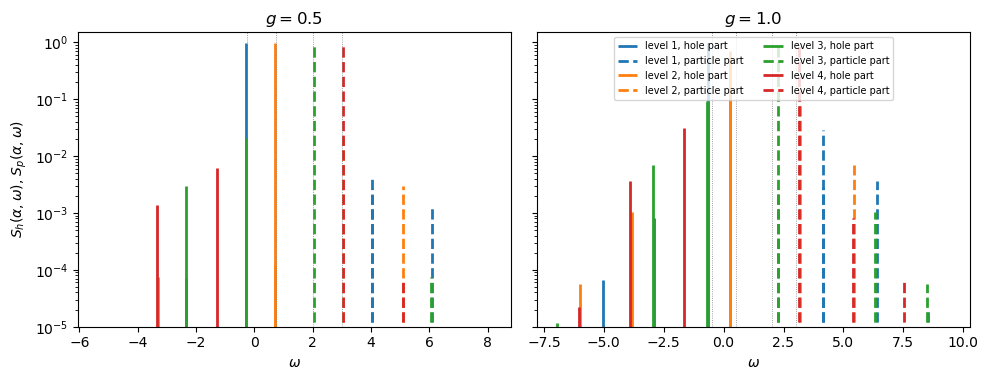

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
for ax, g in zip(axes, (0.5, 1.0)):
    h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
    lp = gf.LehmannPropagator(h, v, N)
    em, Sh = lp.hole_strength()
    ep, Sp = lp.particle_strength()
    colors = ["C0", "C1", "C2", "C3"]
    for level in range(4):
        a = 2 * level                     # the (level, +) spin orbital
        mask = Sh[:, a] > 1e-6
        ax.vlines(em[mask], 1e-6, Sh[mask, a], color=colors[level], lw=2,
                  label=f"level {level + 1}, hole part")
        mask = Sp[:, a] > 1e-6
        ax.vlines(ep[mask], 1e-6, Sp[mask, a], color=colors[level], lw=2,
                  ls="--", label=f"level {level + 1}, particle part")
    eps = np.diag(cc.fock_matrix(h, v, N))
    for e in eps[::2]:
        ax.axvline(e, color="gray", lw=0.6, ls=":")
    ax.set_yscale("log")
    ax.set_ylim(1e-5, 1.5)
    ax.set_xlabel(r"$\omega$")
    ax.set_title(f"$g={g}$")
axes[0].set_ylabel(r"$S_h(\alpha,\omega)$, $S_p(\alpha,\omega)$")
axes[1].legend(fontsize=7, ncol=2, loc="upper center")
plt.tight_layout()
plt.show()

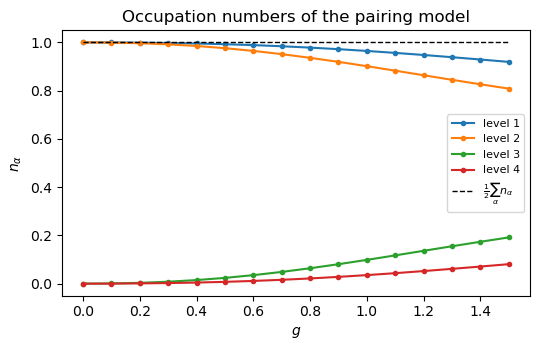

In [4]:
gs = np.linspace(0.0, 1.5, 16)
occ = []
for g in gs:
    h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
    occ.append(gf.LehmannPropagator(h, v, N).occupation()[0][::2])
occ = np.array(occ)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for level in range(4):
    ax.plot(gs, occ[:, level], "o-", ms=3, label=f"level {level + 1}")
ax.plot(gs, occ.sum(1) / 2, "k--", lw=1, label=r"$\frac{1}{2}\sum_\alpha n_\alpha$")
ax.set_xlabel("$g$")
ax.set_ylabel(r"$n_\alpha$")
ax.set_title("Occupation numbers of the pairing model")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
gf.demo_second_order()

The second-order self energy and the Dyson equation, pairing model
  48 poles of Sigma^(2); 2p1h poles at [3.25 4.25 5.25 6.25]  2h1p poles at [-3.5 -2.5 -1.5 -0.5]
  exact removal energies with strength > 1e-3   [ 0.694   0.694  -0.2832 -0.2832 -0.2896 -0.2896 -1.2832 -1.2832 -2.3522 -2.3522 -3.3407 -3.3407]
  Dyson(GF2) removal energies, strength > 1e-3 [-2.514  -2.514  -1.5138 -1.5138 -0.5245 -0.5245 -0.2723 -0.2723  0.7147  0.7147]
  exact occupation  [0.99251 0.99251 0.97603 0.97603 0.02397 0.02397 0.00749 0.00749]
  Dyson(GF2)        [0.9955 0.9955 0.9874 0.9874 0.0126 0.0126 0.0045 0.0045]
  E_FCI = 1.41677428   E(GF2) = 1.43820334   cycles of the static self-consistency: 5


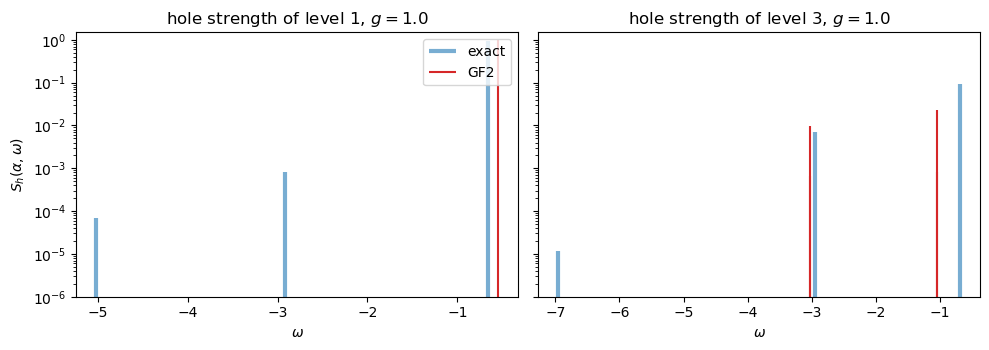

In [6]:
g = 1.0
h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
lp = gf.LehmannPropagator(h, v, N)
res = gf.green_function_energy(h, v, N, scheme="gf2")
sol = res["dyson"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, a in zip(axes, (0, 4)):
    em, Sh = lp.hole_strength()
    mask = Sh[:, a] > 1e-7
    ax.vlines(em[mask], 1e-7, Sh[mask, a], color="C0", lw=3, alpha=0.6, label="exact")
    w = sol["poles"].real[sol["holes"]]
    S = sol["strength"].real[sol["holes"], a]
    mask = S > 1e-7
    ax.vlines(w[mask] + 0.03, 1e-7, S[mask], color="C3", lw=1.5, label="GF2")
    ax.set_yscale("log")
    ax.set_ylim(1e-6, 1.5)
    ax.set_xlabel(r"$\omega$")
    ax.set_title(f"hole strength of level {a // 2 + 1}, $g={g}$")
axes[0].set_ylabel(r"$S_h(\alpha,\omega)$")
axes[0].legend()
plt.tight_layout()
plt.show()

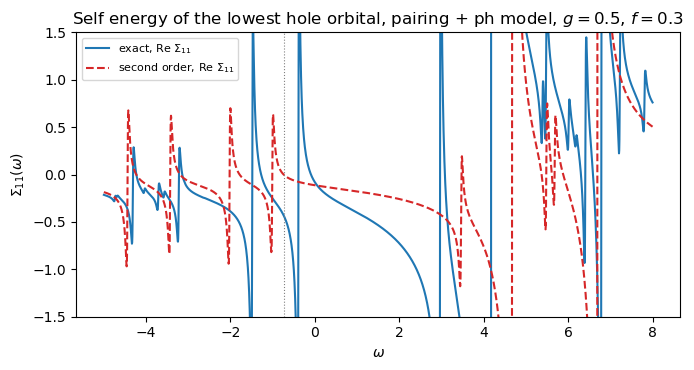

In [7]:
h, v, N = cc.pairing_ph_model(levels=4, particles=4, g=0.5, f=0.3)
hh, vv, C, _ = cc.hartree_fock(h, v, N)
F = cc.fock_matrix(hh, vv, N)
eps = np.diag(F)
lp = gf.LehmannPropagator(hh, vv, N)
E2, ML2, MR2 = gf.self_energy_poles(vv, vv, eps, N)
omegas = np.linspace(-5, 8, 2600)
exact = np.array([gf.exact_self_energy(lp, F, w, eta=0.02)[0, 0] for w in omegas])
second = np.array([gf.self_energy(w + 0.02j, F, E2, ML2, MR2)[0, 0] for w in omegas])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(omegas, exact.real, "C0", label=r"exact, Re $\Sigma_{11}$")
ax.plot(omegas, second.real + F[0, 0] - F[0, 0], "C3--", label=r"second order, Re $\Sigma_{11}$")
ax.set_ylim(-1.5, 1.5)
ax.axvline(eps[0], color="gray", ls=":", lw=0.8)
ax.set_xlabel(r"$\omega$")
ax.set_ylabel(r"$\Sigma_{11}(\omega)$")
ax.set_title("Self energy of the lowest hole orbital, pairing + ph model, $g=0.5$, $f=0.3$")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
gf.demo_channels()

The ring and ladder channels against the RPA (pairing + ph model, g = 0.4, f = 0.3, HF basis)
  RPA energies      [1.376762 1.376762 1.376762 1.376762 2.411596 2.411596 2.411596 2.411596 2.572631 2.572631 2.572631 2.572631 3.603075
 3.603075 3.603075 3.603075]
  ring-series poles [1.376762 1.376762 1.376762 1.376762 2.411596 2.411596 2.411596 2.411596 2.572631 2.572631 2.572631 2.572631 3.603075
 3.603075 3.603075 3.603075]
  largest difference 5.773159728050814e-15
  pp-RPA energies     [-0.685914 -0.149862 -0.149862 -0.149862 -0.111622  2.126212  2.953482  4.941408  4.952009  4.952009  4.952009
  5.578581]
  ladder-series poles [-0.685914 -0.149862 -0.149862 -0.149862 -0.111622  2.126212  2.953482  4.941408  4.952009  4.952009  4.952009
  5.578581]
  largest difference 6.217248937900877e-15


In [9]:
gf.demo_perturbative_content()

Perturbative content: (E_method - E_MPn)/g^(n+1) for small g
  pairing model, 4 levels, 4 particles
     g     (GF2-MP2)/g^3  (GF2-MP3)/g^4  (lad-MP3)/g^4  (ring-MP3)/g^4  (both-MP3)/g^4


   0.025       0.00048         7.2464        -0.1284         7.2270        -0.1479
   0.050       0.00092         3.5671        -0.1277         3.5483        -0.1465


   0.100       0.00171         1.7292        -0.1265         1.7116        -0.1442
   0.200       0.00293         0.8137        -0.1253         0.7981        -0.1409


In [10]:
rows_pairing = gf.demo_pairing()

The pairing model, 4 levels, 4 particles (starting energy -10)


                  HF        MP2        MP3        GF2    parquet ladder-RPA   ring-RPA   both-RPA        CCD        FCI
g = 0.25    1.750000   1.733203   1.730787   1.733256   1.733372   1.730298   1.733198   1.730241   1.730456   1.730460
g = 0.50    1.500000   1.437607   1.421088   1.438203   1.439158   1.412795   1.437509   1.412096   1.416638   1.416774
g = 0.75    1.250000   1.118820   1.070482   1.121015   1.124286   1.017679   1.118265   1.014813   1.051571   1.052726
g = 1.00    1.000000   0.780952   0.680454   0.786152   0.793984   0.274554   0.779155   0.267237   0.630443   0.635548


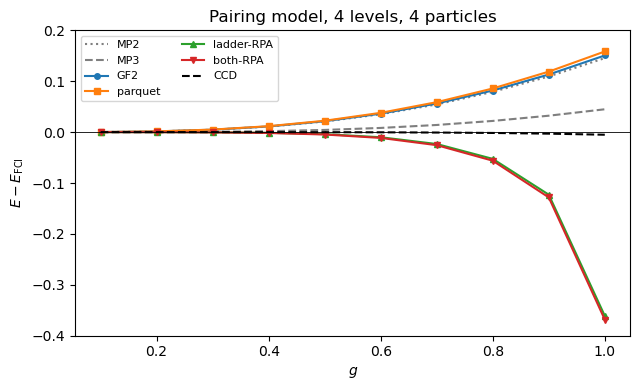

In [11]:
gs = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
keys = ["MP2", "MP3", "GF2", "parquet", "ladder-RPA", "both-RPA", "CCD"]
table = {k: [] for k in keys}
for g in gs:
    h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
    out = gf.compare_methods(h, v, N)
    for k in keys:
        table[k].append(out[k] - out["FCI"])
fig, ax = plt.subplots(figsize=(6.5, 4))
styles = {"MP2": "C7:", "MP3": "C7--", "GF2": "C0o-", "parquet": "C1s-",
          "ladder-RPA": "C2^-", "both-RPA": "C3v-", "CCD": "k--"}
for k in keys:
    ax.plot(gs, table[k], styles[k], ms=4, label=k)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("$g$")
ax.set_ylabel(r"$E-E_{\rm FCI}$")
ax.set_title("Pairing model, 4 levels, 4 particles")
ax.set_ylim(-0.4, 0.2)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [12]:
gf.demo_starting_energy()

Dependence of the energy-independent parquet energy on the starting energy (pairing model, g = 0.5)
  GF2 1.438203   FCI 1.416774
   E_in    eta=0        eta=0.5


    -20   1.438491   1.438491


    -10   1.439158   1.439154


     -5   1.441073   1.441030


     -3   1.443665   1.443871


     -2   1.445589   1.446762


... (4 outputs left out)

      3   1.467452*   1.399923


      5      --      1.434400


     10   1.441237   1.441187


     20   1.438694   1.438693


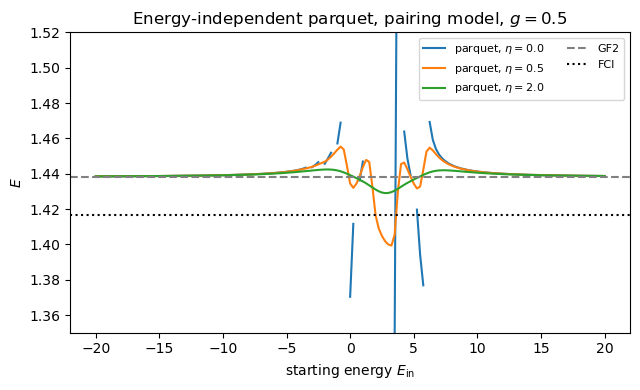

In [13]:
h, v, N = cc.pairing_model(levels=4, particles=4, g=0.5)
e_gf2 = gf.green_function_energy(h, v, N, scheme="gf2")["energy"].real
e_fci = cc.fci_energy(h, v, N)[0]
Eins = np.linspace(-20, 20, 161)
fig, ax = plt.subplots(figsize=(6.5, 4))
for eta, style in ((0.0, "C0-"), (0.5, "C1-"), (2.0, "C2-")):
    es = []
    for Ein in Eins:
        try:
            r = gf.green_function_energy(h, v, N, scheme="parquet",
                                         omega_pp=Ein, omega_ph=Ein, eta=eta)
            es.append(r["energy"].real if r["vertex_info"]["converged"] else np.nan)
        except (np.linalg.LinAlgError, ValueError):
            es.append(np.nan)
    ax.plot(Eins, es, style, label=rf"parquet, $\eta={eta}$")
ax.axhline(e_gf2, color="gray", ls="--", label="GF2")
ax.axhline(e_fci, color="k", ls=":", label="FCI")
ax.set_ylim(1.35, 1.52)
ax.set_xlabel(r"starting energy $E_{\rm in}$")
ax.set_ylabel("$E$")
ax.set_title("Energy-independent parquet, pairing model, $g=0.5$")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [14]:
rows_ph = gf.demo_pairing_ph()
print()
print("particle number of the Dyson solutions at g = 0.5:")
for f in (0.1, 0.2, 0.25, 0.3):
    h, v, N = cc.pairing_ph_model(levels=4, particles=4, g=0.5, f=f)
    hh, vv, _, _ = cc.hartree_fock(h, v, N)
    ns = []
    for s in ("gf2", "ladder-rpa", "both-rpa"):
        r = gf.green_function_energy(hh, vv, N, basis="reference", scheme=s)
        ns.append(f"{s} {np.trace(r['density']).real:.4f}")
    print(f"  f = {f:4.2f}:  " + "   ".join(ns))

The pairing plus particle-hole model (starting energy -10)


                             HF        MP2        GF2    parquet   both-RPA        CCD       CCSD        FCI
g = 0.50, f = 0.025    1.449271   1.374627   1.375445   1.376748   1.339668   1.346912   1.346909   1.347133
g = 0.70, f = 0.050    1.197086   1.049140   1.051807   1.055987   0.912693   0.968186   0.968164   0.969759
g = 1.00, f = 0.050    0.897086   0.637849   0.644650   0.655432   0.334811   0.442445   0.442412   0.450582
g = 0.50, f = 0.250    0.928620   0.698663   0.703575   0.719282   0.171018   0.547897   0.547274   0.551192
g = 1.00, f = 0.500   -0.269764  -0.972193  -0.947687  -0.802812  -1.663232  -1.777932  -1.780542  -1.691737

particle number of the Dyson solutions at g = 0.5:


  f = 0.10:  gf2 4.0000   ladder-rpa 3.9996   both-rpa 3.9996


  f = 0.20:  gf2 3.9999   ladder-rpa 3.9954   both-rpa 3.9953


  f = 0.25:  gf2 3.9998   ladder-rpa 3.9858   both-rpa 3.9855


  f = 0.30:  gf2 3.9997   ladder-rpa 3.8686   both-rpa 3.8762


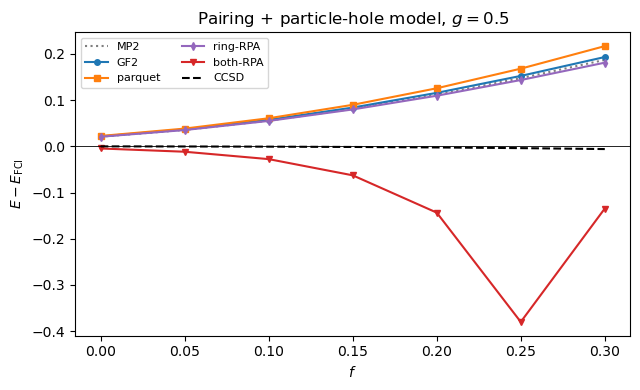

In [15]:
fs = np.array([0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3])
keys = ["MP2", "GF2", "parquet", "ring-RPA", "both-RPA", "CCSD"]
table = {k: [] for k in keys}
for f in fs:
    h, v, N = cc.pairing_ph_model(levels=4, particles=4, g=0.5, f=f)
    out = gf.compare_methods(h, v, N)
    for k in keys:
        table[k].append(out[k] - out["FCI"])
fig, ax = plt.subplots(figsize=(6.5, 4))
styles = {"MP2": "C7:", "GF2": "C0o-", "parquet": "C1s-", "ring-RPA": "C4d-",
          "both-RPA": "C3v-", "CCSD": "k--"}
for k in keys:
    ax.plot(fs, table[k], styles[k], ms=4, label=k)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("$f$")
ax.set_ylabel(r"$E-E_{\rm FCI}$")
ax.set_title("Pairing + particle-hole model, $g=0.5$")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [16]:
rows_lipkin = gf.demo_lipkin()

The Lipkin model (starting energy -10)


                         HF        MP2        GF2    parquet   ring-RPA   both-RPA        CCD       CCSD        FCI
N = 4, V = 0.10   -2.000000  -2.030000  -2.029778  -2.029751  -2.030394  -2.030468  -2.029778  -2.029778  -2.029778
N = 4, V = 0.30   -2.000000  -2.270000  -2.253886  -2.251947  -2.338884  -2.344966  -2.253886  -2.253886  -2.253886
N = 4, V = 0.60   -2.000000  -3.080000  -2.884441  -2.860916  -2.891764  -2.959049  -2.884441  -2.884441  -2.884441
N = 6, V = 0.10   -3.000000  -3.075000  -3.074085  -3.073916  -3.077471  -3.077656  -3.075571  -3.075571  -3.075505
N = 6, V = 0.15   -3.000000  -3.168750  -3.164253  -3.163421  -3.190780  -3.191707  -3.171698  -3.171698  -3.170957
N = 8, V = 0.10   -4.000000  -4.140000  -4.137632  -4.137019  -4.158094  -4.158437  -4.146517  -4.146517  -4.145780


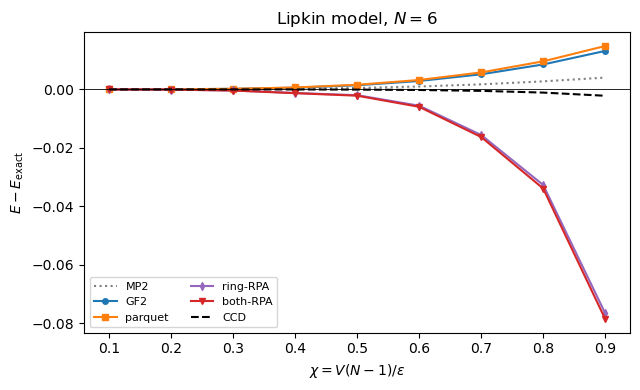

In [17]:
Vs = np.linspace(0.02, 0.18, 9)
keys = ["MP2", "GF2", "parquet", "ring-RPA", "both-RPA", "CCD"]
table = {k: [] for k in keys}
for V in Vs:
    h, v, N = gf.lipkin_model(N=6, V=V)
    out = gf.compare_methods(h, v, N, fci=gf.lipkin_exact_energy(6, V=V), mp3=False)
    for k in keys:
        table[k].append(out[k] - out["FCI"])
fig, ax = plt.subplots(figsize=(6.5, 4))
styles = {"MP2": "C7:", "GF2": "C0o-", "parquet": "C1s-", "ring-RPA": "C4d-",
          "both-RPA": "C3v-", "CCD": "k--"}
for k in keys:
    ax.plot(Vs * 5, table[k], styles[k], ms=4, label=k)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel(r"$\chi = V(N-1)/\varepsilon$")
ax.set_ylabel(r"$E-E_{\rm exact}$")
ax.set_title("Lipkin model, $N=6$")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

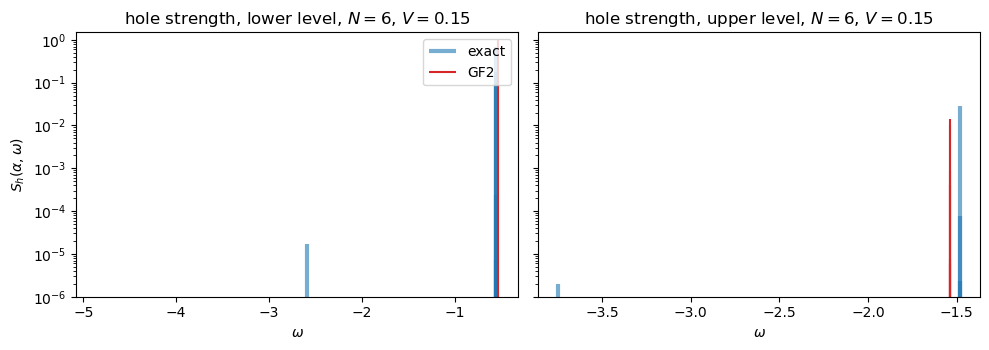

In [18]:
h, v, N = gf.lipkin_model(N=6, V=0.15)
lp = gf.LehmannPropagator(h, v, N)
res = gf.green_function_energy(h, v, N, scheme="gf2")
sol = res["dyson"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, a, name in zip(axes, (0, N), ("lower level", "upper level")):
    em, Sh = lp.hole_strength()
    mask = Sh[:, a] > 1e-7
    ax.vlines(em[mask], 1e-7, Sh[mask, a], color="C0", lw=3, alpha=0.6, label="exact")
    w = sol["poles"].real[sol["holes"]]
    S = sol["strength"].real[sol["holes"], a]
    mask = S > 1e-7
    ax.vlines(w[mask] + 0.02, 1e-7, S[mask], color="C3", lw=1.5, label="GF2")
    ax.set_yscale("log")
    ax.set_ylim(1e-6, 1.5)
    ax.set_xlabel(r"$\omega$")
    ax.set_title(f"hole strength, {name}, $N=6$, $V=0.15$")
axes[0].set_ylabel(r"$S_h(\alpha,\omega)$")
axes[0].legend()
plt.tight_layout()
plt.show()

In [19]:
print(" g   scheme        static sc     + qp energies     CCD        FCI")
for g in (0.5, 1.0):
    h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
    hh, vv, _, _ = cc.hartree_fock(h, v, N)
    f = cc.fock_matrix(hh, vv, N)
    ccd = cc.reference_energy(hh, vv, N) + cc.ccd(f, vv, N)["energy"]
    fci = cc.fci_energy(h, v, N)[0]
    for s in ("gf2", "ladder-rpa", "both-rpa"):
        r1 = gf.green_function_energy(h, v, N, scheme=s)
        r2 = gf.green_function_energy(h, v, N, scheme=s, update_energies=True, mixing=0.3)
        print(f"{g:4.2f} {s:12s} {r1['energy'].real:12.6f} {r2['energy'].real:14.6f}"
              f" {ccd:12.6f} {fci:10.6f}")

 g   scheme        static sc     + qp energies     CCD        FCI
0.50 gf2              1.438203       1.438217     1.416638   1.416774
0.50 ladder-rpa       1.412795       1.413866     1.416638   1.416774


0.50 both-rpa         1.412096       1.413225     1.416638   1.416774
1.00 gf2              0.786152       0.786950     0.630443   0.635548


1.00 ladder-rpa       0.274554       0.586439     0.630443   0.635548


1.00 both-rpa         0.267237       0.582345     0.630443   0.635548
